# Predicting Next-Month Debt Renegotiation
**Data science case study — Lucas de Souza Lima**

The goal is to identify customers who are more likely to renegotiate overdue debt in the following month and rank them for outreach prioritization.

The workflow covers data checks, cleaning, exploratory analysis, temporal model validation and an evaluation using June records. Predictions are assumed to be made at month-end, using information available by that date.

**To run:** place `dados_clientes_case.csv` in the same folder as this notebook and run the cells in order. Package versions are printed below. The original CSV column names and category codes are preserved; an English data dictionary is included in the README. June was inspected during project development, so it is a temporal reference evaluation rather than an independent test set.

## 1. Libraries and data loading

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from matplotlib.ticker import PercentFormatter
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss,
    precision_recall_curve, precision_score, recall_score, f1_score,
)

print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scikit-learn:", sklearn.__version__)

pandas: 2.2.3
numpy: 2.3.5
scikit-learn: 1.8.0


In [2]:
DATA_PATH = Path("dados_clientes_case.csv")
TARGET = "renegociou_no_mes_seguinte"
SEED = 42

BLUE = "#0072B2"
ORANGE = "#D55E00"
GREEN = "#00876C"
GRAY = "#777777"

EMPLOYMENT_LABELS = {"Autônomo": "Self-employed", "Desempregado": "Unemployed", "Empregado": "Employed"}

pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

raw_data = pd.read_csv(DATA_PATH)
print("Rows and columns:", raw_data.shape)
display(raw_data.drop(columns=["nome", "id_cliente"]).head())

Rows and columns: (80000, 17)


,anomes_abt,idade,tempo_de_conta_em_anos,segmento,att_vinculo_empregaticio,vinculo_empregaticio,salario_estimado,saldo_em_conta,reng_ult_3_meses,contato_ult_3meses,qtd_contratos_em_atraso,saldo_em_atraso,combo_produtos_em_atraso,maior_atraso,renegociou_no_mes_seguinte
0,202303,44,26,IA,0,Empregado,9625.1480,2665.2662,0,0,3,29435.4956,"VEICULO, IMOBILIARIO",67,1
1,202303,60,42,IA,0,Desempregado,0.0000,49.8815,0,1,1,28760.0810,"CARTAO, IMOBILIARIO",48,0
2,202304,45,27,IU,0,Empregado,18806.6551,7124.7037,1,0,5,15660.4882,"IMOBILIARIO, VEICULO",40,1
3,202302,64,46,IA,0,Autônomo,21911.4668,26575.0205,0,0,2,19686.2306,CARTAO,66,0
4,202302,65,47,IA,1,Desempregado,NaN,932.3637,1,0,2,22483.2999,"IMOBILIARIO, VEICULO",50,0


In [3]:
column_summary = pd.DataFrame({
    "dtype": raw_data.dtypes.astype(str),
    "missing": raw_data.isna().sum(),
    "missing_pct": 100 * raw_data.isna().mean(),
    "distinct_values": raw_data.nunique(),
})
display(column_summary)

# Each record must have a binary target and a unique customer-month key.
assert raw_data[TARGET].isin([0, 1]).all()
assert not raw_data.duplicated(["anomes_abt", "id_cliente"]).any()

,dtype,missing,missing_pct,distinct_values
anomes_abt,int64,0,0.0000,6
id_cliente,int64,0,0.0000,79997
nome,object,0,0.0000,38081
idade,int64,0,0.0000,57
tempo_de_conta_em_anos,int64,0,0.0000,57
segmento,object,0,0.0000,3
att_vinculo_empregaticio,int64,0,0.0000,2
vinculo_empregaticio,object,0,0.0000,3
salario_estimado,float64,8150,10.1875,57489
saldo_em_conta,float64,5709,7.1362,74291


## 2. Data checks and cleaning

The rules in this section do not use the target. Median imputation will be fitted later, using only the training data for each model.

First, I normalize product combinations as sets. The order of the list does not change which products are present: `CARTAO, VEICULO` and `VEICULO, CARTAO` represent the same combination.

In [4]:
data = raw_data.copy()

product_lists = data["combo_produtos_em_atraso"].str.upper().str.split(",")
products = product_lists.apply(lambda items: {product.strip() for product in items})

data["normalized_overdue_products"] = products.apply(sorted).str.join(", ")
data["has_card"] = products.apply(lambda product_set: int("CARTAO" in product_set))
data["has_mortgage"] = products.apply(lambda product_set: int("IMOBILIARIO" in product_set))
data["has_vehicle"] = products.apply(lambda product_set: int("VEICULO" in product_set))

product_type_count = products.apply(len)
data["product_types_exceed_contracts"] = product_type_count > data["qtd_contratos_em_atraso"]

print("Original product strings:", data["combo_produtos_em_atraso"].nunique())
print("Normalized combinations:", data["normalized_overdue_products"].nunique())
display(data["normalized_overdue_products"].value_counts())

Original product strings: 15
Normalized combinations: 7


,count
normalized_overdue_products,
"CARTAO, IMOBILIARIO, VEICULO",26624
VEICULO,9011
"CARTAO, IMOBILIARIO",9011
"CARTAO, VEICULO",8947
CARTAO,8863
IMOBILIARIO,8819
"IMOBILIARIO, VEICULO",8725


In [5]:
names_per_id = data.groupby("id_cliente")["nome"].nunique()

audit = pd.DataFrame({
    "check": [
        "Duplicate rows",
        "Missing salary",
        "Missing account balance",
        "Negative account tenure",
        "Age below 18",
        "IDs linked to more than one name",
        "Rows with more product types than overdue contracts",
    ],
    "count": [
        raw_data.duplicated().sum(),
        data["salario_estimado"].isna().sum(),
        data["saldo_em_conta"].isna().sum(),
        data["tempo_de_conta_em_anos"].lt(0).sum(),
        data["idade"].lt(18).sum(),
        names_per_id.gt(1).sum(),
        data["product_types_exceed_contracts"].sum(),
    ],
})
display(audit)

,check,count
0,Duplicate rows,0
1,Missing salary,8150
2,Missing account balance,5709
3,Negative account tenure,55
4,Age below 18,91
5,IDs linked to more than one name,3
6,Rows with more product types than overdue contracts,16006


The project scope includes customers aged 18 or older. Records outside that scope are kept in a separate table.

Negative account tenure is treated as unknown (`NaN`), while the received value is retained in an audit column. Missing salary and account balance values are preserved, with indicators that allow the model to recognize these cases.

In [6]:
out_of_scope = data.loc[data["idade"] < 18].copy()
data = data.loc[data["idade"] >= 18].copy()

data["account_tenure_raw"] = data["tempo_de_conta_em_anos"]
negative_tenure = data["tempo_de_conta_em_anos"] < 0
data.loc[negative_tenure, "tempo_de_conta_em_anos"] = np.nan

data["salary_missing"] = data["salario_estimado"].isna().astype("int8")
data["account_balance_missing"] = data["saldo_em_conta"].isna().astype("int8")

print("Records outside the project scope:", len(out_of_scope))
print("Records retained:", len(data))
print("Negative account tenures replaced with missing values:", negative_tenure.sum())

Records outside the project scope: 91
Records retained: 79909
Negative account tenures replaced with missing values: 53


In [7]:
development = data.loc[data["anomes_abt"] < 202306].copy()
june = data.loc[data["anomes_abt"] == 202306].copy()

print("Development (January to May):", len(development))
print("Temporal evaluation (June):", len(june))

valid_tenure = development[["idade", "tempo_de_conta_em_anos"]].dropna()
correlation = valid_tenure["idade"].corr(valid_tenure["tempo_de_conta_em_anos"])
matching_share = valid_tenure["tempo_de_conta_em_anos"].eq(valid_tenure["idade"] - 18).mean()

print(f"Age–account tenure correlation: {correlation:.5f}")
print(f"Account tenure equal to age minus 18: {matching_share:.1%} of valid records")

Development (January to May): 66615
Temporal evaluation (June): 13294
Age–account tenure correlation: 0.99977
Account tenure equal to age minus 18: 90.1% of valid records


Account tenure almost duplicates age in this dataset, so I keep only age among the predictors. Name, customer ID, reference month, the product combination string and audit columns are also excluded from the model.

IDs associated with different names, and rows with more product types than overdue contracts, require clarification at the source. These records are retained: without knowing the field definitions, there is no sound basis for arbitrarily changing values or removing customers.

## 3. Exploratory data analysis

All EDA below uses January through May. Each rate is the number of positive renegotiation outcomes divided by the number of records in that group.

### Target prevalence by month

In [8]:
monthly_rates = development.groupby("anomes_abt")[TARGET].agg(
    customers="size", renegotiations="sum", rate="mean"
)
base_rate = development[TARGET].mean()

display(monthly_rates)
print(f"Mean renegotiation rate in development: {base_rate:.1%}")
print(f"Accuracy of always predicting 'no': {1 - base_rate:.1%}")

,customers,renegotiations,rate
anomes_abt,,,
202301,13300,3687,0.2772
202302,13439,3748,0.2789
202303,13083,3662,0.2799
202304,13340,3771,0.2827
202305,13453,3787,0.2815


Mean renegotiation rate in development: 28.0%
Accuracy of always predicting 'no': 72.0%


Monthly renegotiation rates range from 27.7% to 28.3%. Always predicting “no” would yield roughly 72% accuracy but identify no renegotiations. Model comparison therefore focuses on ranking quality and coverage of positive outcomes. Five months with similar rates are not enough to assess annual seasonality.

### What does missingness tell us?

,vinculo_empregaticio,salary_missing,customers,rate
0,Self-employed,0,6037,0.2433
1,Self-employed,1,669,0.2377
2,Unemployed,0,11905,0.0591
3,Unemployed,1,1390,0.0576
4,Employed,0,41879,0.3177
5,Employed,1,4735,0.6211


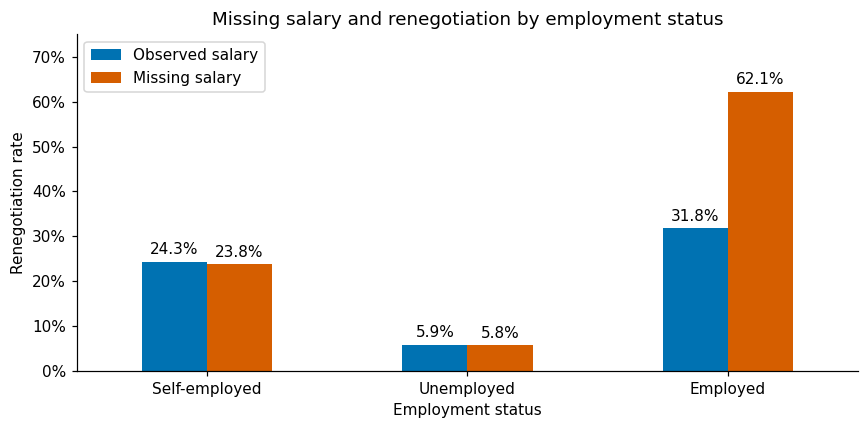

In [9]:
salary_rates = development.groupby(
    ["vinculo_empregaticio", "salary_missing"]
)[TARGET].agg(customers="size", rate="mean").reset_index()
display(salary_rates.replace({"vinculo_empregaticio": EMPLOYMENT_LABELS}))

employment_order = ["Autônomo", "Desempregado", "Empregado"]
salary_table = salary_rates.pivot(
    index="vinculo_empregaticio", columns="salary_missing", values="rate"
).loc[employment_order]
salary_table.columns = ["Observed salary", "Missing salary"]

ax = salary_table.rename(index=EMPLOYMENT_LABELS).plot.bar(color=[BLUE, ORANGE], figsize=(8, 4), rot=0)
ax.set(xlabel="Employment status", ylabel="Renegotiation rate", ylim=(0, 0.75))
ax.set_title("Missing salary and renegotiation by employment status")
ax.yaxis.set_major_formatter(PercentFormatter(1))
for bars in ax.containers:
    ax.bar_label(bars, labels=[f"{bar.get_height():.1%}" for bar in bars], padding=3)
plt.tight_layout()
plt.show()

In [10]:
missing_salary_among_employees = (
    development["salario_estimado"].isna()
    & development["vinculo_empregaticio"].eq("Empregado")
)
missing_balance = development["saldo_em_conta"].isna()

print("Missing balance matches missing salary among employees:",
      missing_balance.eq(missing_salary_among_employees).all())

Missing balance matches missing salary among employees: True


Among employed customers, the renegotiation rate is approximately 62% when salary is missing and 32% when it is observed. Among self-employed and unemployed customers, the difference is small. Removing incomplete records would discard a group with distinct behavior; missing-value indicators preserve that information.

### Product type and employment status

`has_mortgage = 1` means the overdue-product field contains `IMOBILIARIO`. It does not establish home ownership or the number of mortgage contracts.

,customers,rate
has_mortgage,,
Without mortgage,22401,0.0608
With mortgage,44214,0.3911


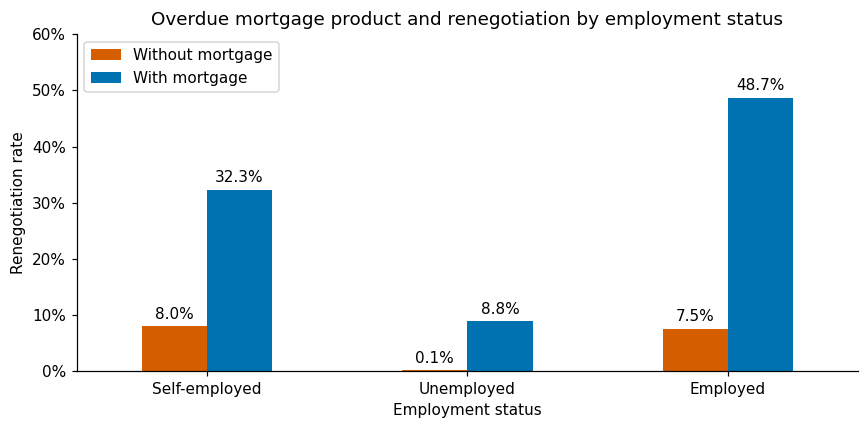

In [11]:
product_rates = development.groupby("has_mortgage")[TARGET].agg(
    customers="size", rate="mean"
)
display(product_rates.rename(index={0: "Without mortgage", 1: "With mortgage"}))

product_by_employment = development.groupby(
    ["vinculo_empregaticio", "has_mortgage"]
)[TARGET].mean().unstack().loc[employment_order]
product_by_employment.columns = ["Without mortgage", "With mortgage"]

ax = product_by_employment.rename(index=EMPLOYMENT_LABELS).plot.bar(color=[ORANGE, BLUE], figsize=(8, 4), rot=0)
ax.set(xlabel="Employment status", ylabel="Renegotiation rate", ylim=(0, 0.60))
ax.set_title("Overdue mortgage product and renegotiation by employment status")
ax.yaxis.set_major_formatter(PercentFormatter(1))
for bars in ax.containers:
    ax.bar_label(bars, labels=[f"{bar.get_height():.1%}" for bar in bars], padding=3)
plt.tight_layout()
plt.show()

The overall renegotiation rate is close to 39% with an overdue mortgage product and 6% without one. The difference appears in all three employment groups, but the level varies substantially: among unemployed customers with an overdue mortgage product, the rate is around 9%. Product type alone does not describe the full customer profile.

### Debt amount and days past due

Quartiles are calculated across the full development dataset: Q1 contains the lowest overdue balances and Q4 the highest. The bands below are used only for visualization; models receive the original numeric values.

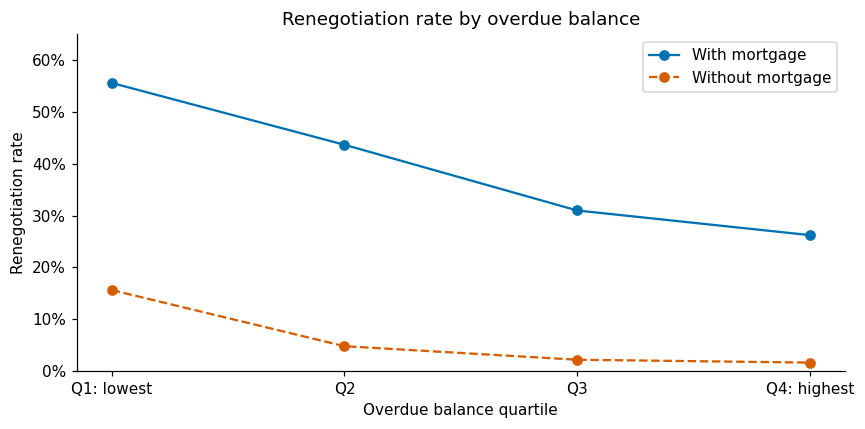

has_mortgage,Without mortgage,With mortgage
debt_quartile,,
Q1: lowest,0.1565,0.5559
Q2,0.0482,0.4367
Q3,0.0221,0.3100
Q4: highest,0.0166,0.2624


In [12]:
development["debt_quartile"] = pd.qcut(
    development["saldo_em_atraso"], q=4,
    labels=["Q1: lowest", "Q2", "Q3", "Q4: highest"],
)
debt_rates = development.groupby(
    ["debt_quartile", "has_mortgage"], observed=True
)[TARGET].mean().unstack()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(debt_rates.index.astype(str), debt_rates[1], "o-", color=BLUE, label="With mortgage")
ax.plot(debt_rates.index.astype(str), debt_rates[0], "o--", color=ORANGE, label="Without mortgage")
ax.set(xlabel="Overdue balance quartile", ylabel="Renegotiation rate", ylim=(0, 0.65))
ax.set_title("Renegotiation rate by overdue balance")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend()
plt.tight_layout()
plt.show()
display(debt_rates.rename(columns={0: "Without mortgage", 1: "With mortgage"}))

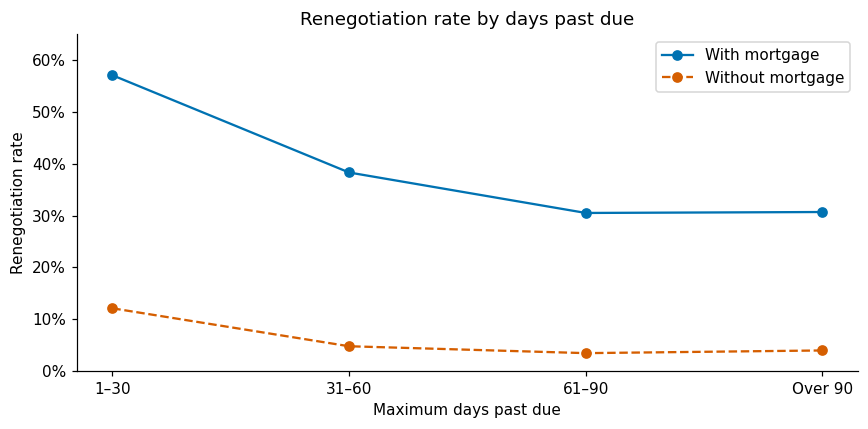

In [13]:
development["overdue_band"] = pd.cut(
    development["maior_atraso"], bins=[0, 30, 60, 90, np.inf],
    labels=["1–30", "31–60", "61–90", "Over 90"],
)
overdue_rates = development.groupby(
    ["overdue_band", "has_mortgage"], observed=True
)[TARGET].mean().unstack()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(overdue_rates.index.astype(str), overdue_rates[1], "o-", color=BLUE, label="With mortgage")
ax.plot(overdue_rates.index.astype(str), overdue_rates[0], "o--", color=ORANGE, label="Without mortgage")
ax.set(xlabel="Maximum days past due", ylabel="Renegotiation rate", ylim=(0, 0.65))
ax.set_title("Renegotiation rate by days past due")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend()
plt.tight_layout()
plt.show()

Within both the mortgage and non-mortgage groups, Q4 has the lowest renegotiation rate. Among customers with an overdue mortgage product, the rate falls from 55.6% in Q1 to 26.2% in Q4. Prioritizing the largest balances therefore does not, by itself, prioritize the customers most likely to renegotiate.

For days past due, the decline is steeper across the first bands; above 60 days, rates are similar. These are group-level associations, not causal effects or rules for every individual. The target records renegotiation without measuring the amount actually repaid.

### Recent history, segment and age

In [14]:
contact_history = development.groupby("contato_ult_3meses")[TARGET].agg(customers="size", rate="mean")
previous_renegotiation = development.groupby("reng_ult_3_meses")[TARGET].agg(customers="size", rate="mean")
segment = development.groupby("segmento")[TARGET].agg(customers="size", rate="mean")

development["age_band"] = pd.cut(
    development["idade"], bins=[17, 29, 44, 59, np.inf],
    labels=["18–29", "30–44", "45–59", "60+"],
)
age = development.groupby("age_band", observed=True)[TARGET].agg(customers="size", rate="mean")

print("Contact in the previous three months")
display(contact_history.rename(index={0: "No", 1: "Yes"}))
print("Renegotiation in the previous three months")
display(previous_renegotiation.rename(index={0: "No", 1: "Yes"}))
print("Segment")
display(segment)
print("Age")
display(age)

Contact in the previous three months


,customers,rate
contato_ult_3meses,,
No,46736,0.2658
Yes,19879,0.3134


Renegotiation in the previous three months


,customers,rate
reng_ult_3_meses,,
No,51418,0.2603
Yes,15197,0.3468


Segment


,customers,rate
segmento,,
IA,33226,0.2517
IP,13335,0.3348
IU,20054,0.2905


Age


,customers,rate
age_band,,
18–29,21645,0.2569
30–44,21175,0.2882
45–59,13740,0.2929
60+,10055,0.2951


The renegotiation rate is 31.3% with recent contact and 26.6% without it. With a recent renegotiation, it is 34.7%, compared with 26.0% without one. These histories distinguish groups but do not show that contact caused renegotiation.

IP, IU and IA are segment codes whose meanings are not defined in the case brief. The rate is highest in IP and lowest in IA. Customers aged 18–29 have a rate near 26%, compared with roughly 29% in the other age bands.

## 4. Model setup

All four model families receive the same 16 features. The reference month defines training and validation periods and is not used as a predictor. The two categorical fields are transformed with one-hot encoding.

In [15]:
features = [
    "idade", "segmento", "att_vinculo_empregaticio", "vinculo_empregaticio",
    "salario_estimado", "saldo_em_conta", "reng_ult_3_meses", "contato_ult_3meses",
    "qtd_contratos_em_atraso", "saldo_em_atraso", "maior_atraso",
    "salary_missing", "account_balance_missing",
    "has_card", "has_mortgage", "has_vehicle",
]

categorical_columns = ["segmento", "vinculo_empregaticio"]
numeric_columns = [column for column in features if column not in categorical_columns]

print("Features before one-hot encoding:", len(features))

Features before one-hot encoding: 16


### Preprocessing

Medians, scaling parameters and categories are learned only from training records. The `Pipeline` applies those fitted transformations to validation data, preventing the evaluation month from influencing preprocessing.

Scaling is used for logistic regression; trees do not require it. This initial comparison uses neither class weights nor resampling. The families are evaluated with the observed class distribution and ranking-oriented metrics.

In [16]:
numeric_transformer = Pipeline([
    ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
])

logistic_numeric_transformer = Pipeline([
    ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("scale", StandardScaler()),
])

categorical_transformer = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="__MISSING__", keep_empty_features=True)),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_columns),
    ("categorical", categorical_transformer, categorical_columns),
])

logistic_preprocessor = ColumnTransformer([
    ("numeric", logistic_numeric_transformer, numeric_columns),
    ("categorical", categorical_transformer, categorical_columns),
])

### Constant baseline and logistic regression

The constant baseline assigns the training target prevalence to every customer. Logistic regression provides a simple regularized alternative: smaller values of `C` increase the coefficient penalty.

In [17]:
constant_model = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", DummyClassifier(strategy="prior")),
])

logistic_model = Pipeline([
    ("preprocess", clone(logistic_preprocessor)),
    ("model", LogisticRegression(
        C=0.1, max_iter=2000, tol=1e-6, random_state=SEED,
    )),
])

### Decision tree and gradient boosting

For the decision tree, I limit depth and the minimum number of records per leaf. For boosting, I control leaf count, iterations, learning rate and L2 regularization. `early_stopping` is disabled because configurations are compared using the explicit temporal splits below.

In [18]:
tree_model = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", DecisionTreeClassifier(
        max_depth=5, min_samples_leaf=200, random_state=SEED,
    )),
])

boosting_model = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", HistGradientBoostingClassifier(
        max_leaf_nodes=7,
        max_iter=300,
        learning_rate=0.08,
        min_samples_leaf=100,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=SEED,
    )),
])

## 5. Temporal validation and model comparison

I use an expanding training window: January–February to evaluate March records, January–March to evaluate April, and January–April to evaluate May. For each reference month, the target is renegotiation in the following month.

The selection criterion is **mean AP across the three validation months**. Average precision combines the precision values obtained as a score-ranked list expands, weighting each by the corresponding increase in recall. It does not require selecting a single classification threshold. ROC-AUC, Brier score and precision/recall among the top 20% provide complementary views.

The next two functions handle calculations reused across models. The first evaluates a selected share of the portfolio; the second applies the same temporal validation protocol to each model.

In [19]:
def evaluate_queue(target, scores, fraction=0.20):
    """Measure the positive outcomes within the top-scoring fraction."""
    target = np.asarray(target, dtype=int)
    scores = np.asarray(scores, dtype=float)

    count = int(np.ceil(fraction * len(target)))
    order = np.argsort(-scores, kind="stable")
    selected = order[:count]
    positives_in_queue = int(target[selected].sum())
    total_positives = int(target.sum())
    precision = positives_in_queue / count

    return {
        "fraction": fraction,
        "selected": count,
        "positives": positives_in_queue,
        "precision": precision,
        "recall": positives_in_queue / total_positives if total_positives else np.nan,
        "max_recall": min(1, count / total_positives) if total_positives else np.nan,
        "lift": precision / target.mean() if total_positives else np.nan,
    }

In [20]:
def validate_model(model, data, columns, months):
    """Fit from scratch at each time split and return validation metrics and predictions."""
    results = []
    predictions = []

    for month in months:
        training = data.loc[data["anomes_abt"] < month]
        validation_month = data.loc[data["anomes_abt"] == month]

        # clone creates an unfitted copy, without information from previous fits.
        month_model = clone(model)
        month_model.fit(training[columns], training[TARGET])
        training_scores = month_model.predict_proba(training[columns])[:, 1]
        validation_scores = month_model.predict_proba(validation_month[columns])[:, 1]
        queue = evaluate_queue(validation_month[TARGET], validation_scores)

        results.append({
            "month": month,
            "AP_train": average_precision_score(training[TARGET], training_scores),
            "AP": average_precision_score(validation_month[TARGET], validation_scores),
            "ROC_AUC": roc_auc_score(validation_month[TARGET], validation_scores),
            "Brier": brier_score_loss(validation_month[TARGET], validation_scores),
            "precision_top20": queue["precision"],
            "recall_top20": queue["recall"],
        })
        predictions.append(pd.DataFrame({
            "month": month,
            "observed": validation_month[TARGET].to_numpy(),
            "score": validation_scores,
        }))

    return pd.DataFrame(results), pd.concat(predictions, ignore_index=True)

### Candidate configurations

There are ten configurations, all evaluated with the same features and validation months. For example, `model__C` refers to parameter `C` in the pipeline step named `model`.

In [21]:
validation_months = [202303, 202304, 202305]

models = {
    "Constant": constant_model,
    "Logistic regression": logistic_model,
    "Decision tree": tree_model,
    "Gradient boosting": boosting_model,
}

configurations = [
    {"id": "constant", "family": "Constant", "parameters": {}},
    {"id": "logistic_C0.01", "family": "Logistic regression", "parameters": {"model__C": 0.01}},
    {"id": "logistic_C0.1", "family": "Logistic regression", "parameters": {"model__C": 0.1}},
    {"id": "logistic_C1", "family": "Logistic regression", "parameters": {"model__C": 1.0}},
    {"id": "tree_d3", "family": "Decision tree", "parameters": {"model__max_depth": 3}},
    {"id": "tree_d5", "family": "Decision tree", "parameters": {"model__max_depth": 5}},
    {"id": "boosting_l7_i150", "family": "Gradient boosting",
     "parameters": {"model__max_leaf_nodes": 7, "model__max_iter": 150}},
    {"id": "boosting_l7_i300", "family": "Gradient boosting",
     "parameters": {"model__max_leaf_nodes": 7, "model__max_iter": 300}},
    {"id": "boosting_l15_i150", "family": "Gradient boosting",
     "parameters": {"model__max_leaf_nodes": 15, "model__max_iter": 150}},
    {"id": "boosting_l15_i300", "family": "Gradient boosting",
     "parameters": {"model__max_leaf_nodes": 15, "model__max_iter": 300}},
]

In [22]:
configuration_results = []
validation_predictions = {}
configured_models = {}

for configuration in configurations:
    identifier = configuration["id"]
    family = configuration["family"]
    model = clone(models[family])
    model.set_params(**configuration["parameters"])

    result, predictions = validate_model(model, development, features, validation_months)
    result["id"] = identifier
    result["family"] = family

    configuration_results.append(result)
    validation_predictions[identifier] = predictions
    configured_models[identifier] = model

search_results = pd.concat(configuration_results, ignore_index=True)
search_results["AP_gap"] = search_results["AP_train"] - search_results["AP"]

search_summary = search_results.groupby(["id", "family"], as_index=False).agg(
    AP_mean=("AP", "mean"),
    AP_min=("AP", "min"),
    AP_max=("AP", "max"),
    train_validation_gap=("AP_gap", "mean"),
)
display(search_summary.sort_values("AP_mean", ascending=False))

,id,family,AP_mean,AP_min,AP_max,train_validation_gap
3,boosting_l7_i300,Gradient boosting,0.8197,0.8128,0.8281,0.0139
1,boosting_l15_i300,Gradient boosting,0.8192,0.8113,0.8273,0.0359
0,boosting_l15_i150,Gradient boosting,0.8189,0.8114,0.8276,0.0176
2,boosting_l7_i150,Gradient boosting,0.8149,0.8087,0.8236,0.0065
6,logistic_C0.1,Logistic regression,0.7413,0.7344,0.7532,-0.0020
7,logistic_C1,Logistic regression,0.7413,0.7343,0.7532,-0.0020
5,logistic_C0.01,Logistic regression,0.7410,0.7343,0.7528,-0.0018
9,tree_d5,Decision tree,0.6626,0.6515,0.6703,-0.0030
8,tree_d3,Decision tree,0.5288,0.5223,0.5329,0.0007
4,constant,Constant,0.2814,0.2799,0.2827,-0.0026


In [23]:
best_configurations = search_summary.sort_values(["AP_mean", "id"], ascending=[False, True])
best_configurations = best_configurations.drop_duplicates("family")
selected_ids = best_configurations.set_index("family")["id"].to_dict()

validation = search_results.loc[search_results["id"].isin(selected_ids.values())].copy()
model_summary = validation.groupby("family").agg(
    AP_mean=("AP", "mean"),
    AP_min=("AP", "min"),
    AP_max=("AP", "max"),
    ROC_AUC=("ROC_AUC", "mean"),
    precision_top20=("precision_top20", "mean"),
    recall_top20=("recall_top20", "mean"),
).sort_values("AP_mean", ascending=False)

selected_family = model_summary["AP_mean"].idxmax()
display(model_summary)
print("Selected model family:", selected_family)
print("Selected configuration:", selected_ids[selected_family])

,AP_mean,AP_min,AP_max,ROC_AUC,precision_top20,recall_top20
family,,,,,,
Gradient boosting,0.8197,0.8128,0.8281,0.9177,0.8037,0.5713
Logistic regression,0.7413,0.7344,0.7532,0.8812,0.7330,0.5211
Decision tree,0.6626,0.6515,0.6703,0.8612,0.6770,0.4813
Constant,0.2814,0.2799,0.2827,0.5000,0.2797,0.1989


Selected model family: Gradient boosting
Selected configuration: boosting_l7_i300


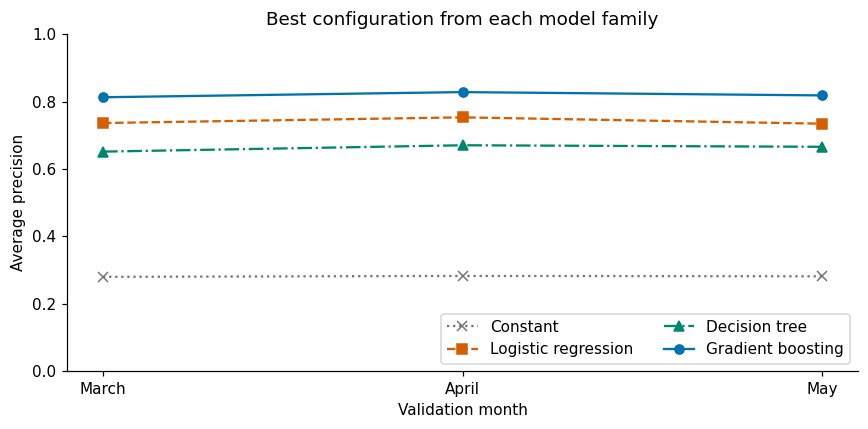

In [24]:
ap_by_month = validation.pivot(index="month", columns="family", values="AP")
month_labels = ["March", "April", "May"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(month_labels, ap_by_month["Constant"], "x:", color=GRAY, label="Constant")
ax.plot(month_labels, ap_by_month["Logistic regression"], "s--", color=ORANGE, label="Logistic regression")
ax.plot(month_labels, ap_by_month["Decision tree"], "^-.", color=GREEN, label="Decision tree")
ax.plot(month_labels, ap_by_month["Gradient boosting"], "o-", color=BLUE, label="Gradient boosting")
ax.set(ylim=(0, 1), xlabel="Validation month", ylabel="Average precision")
ax.set_title("Best configuration from each model family")
ax.legend(loc="lower right", ncol=2)
plt.tight_layout()
plt.show()

Gradient boosting has the highest mean AP: **0.820**, compared with 0.741 for logistic regression, 0.663 for the decision tree and 0.281 for the constant baseline. It also leads in all three validation months.

The configuration with **7 leaves and 300 iterations** was selected by mean AP. Its advantage over 15 leaves and 300 iterations is small, around 0.0005. The smaller training–validation gap (0.014 versus 0.036) further supports the less complex configuration, but does not prove that overfitting is absent.

The improvement over logistic regression is consistent with nonlinear relationships and interactions. This comparison does not isolate the contribution of either mechanism.

## 6. Feature reduction and importance

I compare the 16 features with two smaller sets: 14 features, excluding age and segment; and 12, also excluding contact and renegotiation histories. Each family's selected hyperparameters and temporal splits are held fixed.

In [25]:
features_14 = [column for column in features if column not in ["idade", "segmento"]]
features_12 = [column for column in features_14
                if column not in ["reng_ult_3_meses", "contato_ult_3meses"]]
feature_sets = {16: features, 14: features_14, 12: features_12}

reduction_results = []

for family in ["Logistic regression", "Gradient boosting"]:
    for count, columns in feature_sets.items():
        categorical = [column for column in columns if column in categorical_columns]
        numeric = [column for column in columns if column not in categorical]

        transformer = logistic_numeric_transformer if family == "Logistic regression" else numeric_transformer
        reduction_preprocessor = ColumnTransformer([
            ("numeric", clone(transformer), numeric),
            ("categorical", clone(categorical_transformer), categorical),
        ])
        reduced_model = clone(configured_models[selected_ids[family]])
        reduced_model.set_params(preprocess=reduction_preprocessor)

        result, _ = validate_model(reduced_model, development, columns, validation_months)
        result["family"] = family
        result["n_features"] = count
        reduction_results.append(result[["family", "n_features", "month", "AP"]])

feature_reduction = pd.concat(reduction_results, ignore_index=True)
display(feature_reduction.pivot_table(index="family", columns="n_features", values="AP"))

n_features,12,14,16
family,,,
Gradient boosting,0.8083,0.8165,0.8197
Logistic regression,0.7318,0.7401,0.7413


In [26]:
reduction_by_month = feature_reduction.pivot(index=["family", "month"], columns="n_features", values="AP")
display(reduction_by_month)

lower_ap_with_14 = (reduction_by_month[14] < reduction_by_month[16]).all()
lower_ap_with_12 = (reduction_by_month[12] < reduction_by_month[16]).all()
print("Both smaller feature sets lost AP in every split:", lower_ap_with_14 and lower_ap_with_12)

n_features                     12     14     16
family              month                      
Gradient boosting   202303 0.8009 0.8102 0.8128
                    202304 0.8145 0.8242 0.8281
                    202305 0.8094 0.8149 0.8183
Logistic regression 202303 0.7268 0.7356 0.7363
                    202304 0.7428 0.7518 0.7532
                    202305 0.7258 0.7329 0.7344

Both smaller feature sets lost AP in every split: True


Mean AP for boosting decreases from 0.820 to 0.816 with 14 features and to 0.808 with 12. Both smaller sets lose AP in every month for both model families evaluated. I retain all 16 features.

### Grouped permutation importance

I train boosting on January–April and evaluate it on May. Each feature group is shuffled five times to measure the decrease in AP. Related columns use the same row permutation, preserving relationships within the group.

In [27]:
feature_groups = {
    "Income, balance and employment": [
        "vinculo_empregaticio", "att_vinculo_empregaticio", "salario_estimado",
        "saldo_em_conta", "salary_missing", "account_balance_missing",
    ],
    "Products and contracts": ["has_card", "has_mortgage", "has_vehicle", "qtd_contratos_em_atraso"],
    "Overdue balance": ["saldo_em_atraso"],
    "Maximum days past due": ["maior_atraso"],
    "Recent renegotiation": ["reng_ult_3_meses"],
    "Recent contact": ["contato_ult_3meses"],
    "Age": ["idade"],
    "Segment": ["segmento"],
}

importance_training = development.loc[development["anomes_abt"] < 202305]
may = development.loc[development["anomes_abt"] == 202305]
may_model = clone(configured_models[selected_ids["Gradient boosting"]])
may_model.fit(importance_training[features], importance_training[TARGET])

may_scores = may_model.predict_proba(may[features])[:, 1]
reference_ap = average_precision_score(may[TARGET], may_scores)

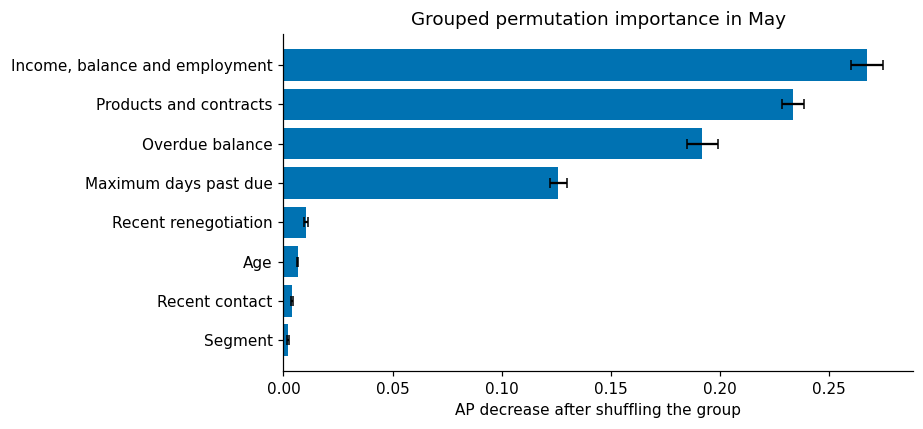

In [28]:
rng = np.random.default_rng(SEED + 1)
importance_results = []

for group, columns in feature_groups.items():
    drops = []
    for repeat in range(5):
        order = rng.permutation(len(may))
        shuffled_data = may[features].copy()
        for column in columns:
            shuffled_data[column] = may[column].to_numpy()[order]

        shuffled_scores = may_model.predict_proba(shuffled_data)[:, 1]
        shuffled_ap = average_precision_score(may[TARGET], shuffled_scores)
        drops.append(reference_ap - shuffled_ap)

    importance_results.append({
        "group": group, "mean": np.mean(drops), "std": np.std(drops, ddof=1),
    })

importance = pd.DataFrame(importance_results).set_index("group").sort_values("mean")

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.barh(importance.index, importance["mean"], xerr=importance["std"], color=BLUE, capsize=3)
ax.set(xlabel="AP decrease after shuffling the group", title="Grouped permutation importance in May")
plt.tight_layout()
plt.show()

The model depends mainly on the financial and product groups, followed by overdue balance and days past due. Error bars show variation across the five shuffles.

Importance measures this fitted model's dependence on a feature group. It does not measure causality or assign the importance of an entire group to a single column.

## 7. Classification threshold

A capacity-based list selects a fixed number of customers. A threshold rule flags customers whose score exceeds a chosen value. To illustrate the latter, I find the threshold with the highest F1 using the selected model's March–May validation predictions. June does not enter this calculation.

In [29]:
selected_predictions = validation_predictions[selected_ids[selected_family]]
validation_precision, validation_recall, thresholds = precision_recall_curve(
    selected_predictions["observed"], selected_predictions["score"]
)

# The last precision/recall pair has no corresponding threshold.
validation_precision = validation_precision[:-1]
validation_recall = validation_recall[:-1]
denominator = validation_precision + validation_recall
validation_f1 = 2 * validation_precision * validation_recall / np.maximum(denominator, 1e-12)

best_f1 = validation_f1.max()
ties = np.isclose(validation_f1, best_f1, rtol=0, atol=1e-12)
f1_threshold = float(thresholds[ties][-1])  # choose the highest threshold in a tie

print(f"Threshold selected on development data: {f1_threshold:.4f}")

Threshold selected on development data: 0.3249


## 8. Temporal evaluation on June records

I now fit the selected configurations on the full development dataset and apply them to June records. Features describe June, while the target indicates renegotiation in July. Since June was already inspected during the project, generalization must be confirmed on new months.

In [30]:
final_models = {}
june_scores = {}
june_results = []

for family in ["Constant", "Logistic regression", "Decision tree", "Gradient boosting"]:
    model = clone(configured_models[selected_ids[family]])
    model.fit(development[features], development[TARGET])
    scores = model.predict_proba(june[features])[:, 1]
    queue = evaluate_queue(june[TARGET], scores)

    final_models[family] = model
    june_scores[family] = scores
    june_results.append({
        "family": family,
        "AP": average_precision_score(june[TARGET], scores),
        "ROC_AUC": roc_auc_score(june[TARGET], scores),
        "precision_top20": queue["precision"],
        "recall_top20": queue["recall"],
        "Brier": brier_score_loss(june[TARGET], scores),
    })

june_metrics = pd.DataFrame(june_results).set_index("family")
display(june_metrics)

final_model = final_models[selected_family]
final_scores = june_scores[selected_family]
print(f"June: {june[TARGET].sum()} positive outcomes among {len(june)} customers ({june[TARGET].mean():.2%}).")

,AP,ROC_AUC,precision_top20,recall_top20,Brier
family,,,,,
Constant,0.2846,0.5000,0.2862,0.2011,0.2036
Logistic regression,0.7479,0.8816,0.7345,0.5161,0.1248
Decision tree,0.6647,0.8634,0.6886,0.4839,0.1303
Gradient boosting,0.8271,0.9195,0.8123,0.5708,0.1033


June: 3784 positive outcomes among 13294 customers (28.46%).


### How does queue size affect results?

**Precision** is the share of positive outcomes among selected customers. **Recall** is the share of all positive outcomes captured by the list. **Lift** compares precision with overall prevalence. **Maximum recall** is the theoretical ceiling for that list size, even with a perfect ranking.

These are retrospective selection scenarios. The dataset does not establish that the team contacted the customers selected by the model or that contact caused their renegotiations.

In [31]:
capacity_results = []
for fraction in [0.05, 0.10, 0.20, 0.30, 0.50]:
    capacity_results.append(evaluate_queue(june[TARGET], final_scores, fraction))

capacities = pd.DataFrame(capacity_results)
display(capacities)

top20 = capacities.loc[capacities["fraction"] == 0.20].iloc[0]
expected_random_positives = top20["selected"] * june[TARGET].mean()
print(f"Top 20%: {int(top20['selected'])} customers, including {int(top20['positives'])} positive outcomes.")
print(f"A random list of the same size would contain {expected_random_positives:.0f} positive outcomes in expectation.")

,fraction,selected,positives,precision,recall,max_recall,lift
0,0.0500,665,662,0.9955,0.1749,0.1757,3.4974
1,0.1000,1330,1256,0.9444,0.3319,0.3515,3.3177
2,0.2000,2659,2160,0.8123,0.5708,0.7027,2.8539
3,0.3000,3989,2817,0.7062,0.7445,1.0000,2.4810
4,0.5000,6647,3618,0.5443,0.9561,1.0000,1.9123


Top 20%: 2659 customers, including 2160 positive outcomes.
A random list of the same size would contain 757 positive outcomes in expectation.


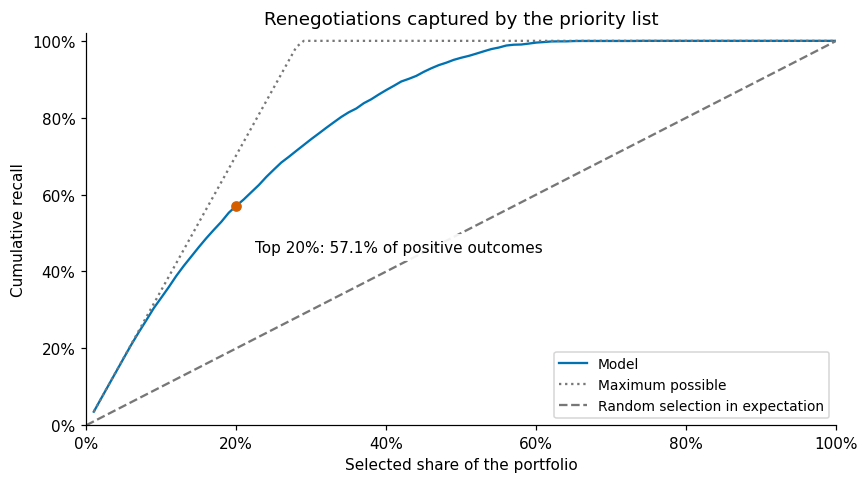

In [32]:
curve_results = []
for fraction in np.linspace(0.01, 1, 100):
    curve_results.append(evaluate_queue(june[TARGET], final_scores, fraction))
capacity_curve = pd.DataFrame(curve_results)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(capacity_curve["fraction"], capacity_curve["recall"], color=BLUE, label="Model")
ax.plot(capacity_curve["fraction"], capacity_curve["max_recall"], color=GRAY, linestyle=":", label="Maximum possible")
ax.plot([0, 1], [0, 1], color=GRAY, linestyle="--", label="Random selection in expectation")
ax.scatter(0.20, top20["recall"], color=ORANGE, zorder=3)
ax.annotate(f"Top 20%: {top20['recall']:.1%} of positive outcomes",
            (0.20, top20["recall"]), xytext=(12, -30), textcoords="offset points",
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9})
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="Selected share of the portfolio", ylabel="Cumulative recall")
ax.set_title("Renegotiations captured by the priority list")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

The **top-scoring 20%** contain 2,659 customers and 2,160 of the 3,784 observed positive outcomes: **81.2% precision**, **57.1% recall** and **2.85 lift**. A random list of the same size would contain about 757 positive outcomes in expectation.

The recall ceiling for 2,659 slots is 2,659 / 3,784 = 70.3%. Selecting 30% of the portfolio increases recall to 74.4%, with 70.6% precision. Queue size depends on operational capacity.

### Score deciles and calibration

In [33]:
june_evaluation = pd.DataFrame({"observed": june[TARGET].to_numpy(), "score": final_scores})
score_order = june_evaluation["score"].rank(method="first", ascending=False)
june_evaluation["decile"] = pd.qcut(score_order, q=10, labels=range(1, 11))

deciles = june_evaluation.groupby("decile", observed=True).agg(
    customers=("observed", "size"),
    renegotiated=("observed", "sum"),
    rate=("observed", "mean"),
    mean_score=("score", "mean"),
)
deciles["lift"] = deciles["rate"] / june[TARGET].mean()
deciles["cumulative_recall"] = deciles["renegotiated"].cumsum() / deciles["renegotiated"].sum()
display(deciles)

,customers,renegotiated,rate,mean_score,lift,cumulative_recall
decile,,,,,,
1,1330,1256,0.9444,0.9143,3.3177,0.3319
2,1329,904,0.6802,0.6912,2.3897,0.5708
3,1329,657,0.4944,0.5000,1.7368,0.7445
4,1330,483,0.3632,0.3405,1.2759,0.8721
5,1329,318,0.2393,0.2095,0.8406,0.9561
6,1329,149,0.1121,0.1065,0.3939,0.9955
7,1330,16,0.0120,0.0353,0.0423,0.9997
8,1329,1,0.0008,0.0113,0.0026,1.0000
9,1329,0,0.0000,0.0034,0.0000,1.0000


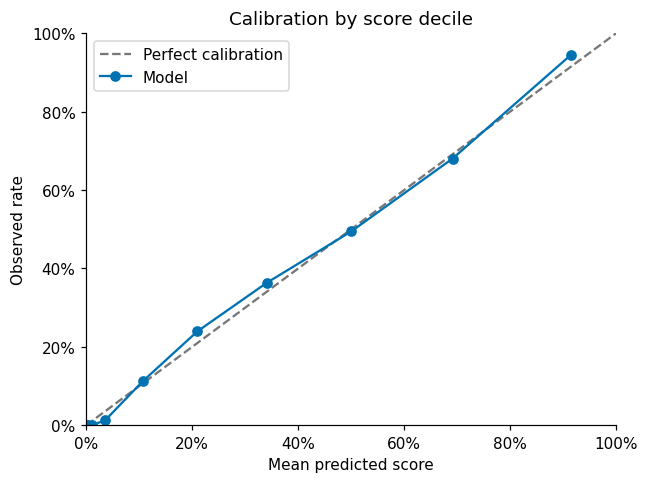

Mean score: 28.13%
Observed rate: 28.46%
Largest gap across deciles: 3.0 percentage points


In [34]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot([0, 1], [0, 1], color=GRAY, linestyle="--", label="Perfect calibration")
ax.plot(deciles["mean_score"], deciles["rate"], "o-", color=BLUE, label="Model")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean predicted score", ylabel="Observed rate")
ax.set_title("Calibration by score decile")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend()
plt.tight_layout()
plt.show()

largest_gap = (deciles["mean_score"] - deciles["rate"]).abs().max()
print(f"Mean score: {final_scores.mean():.2%}")
print(f"Observed rate: {june[TARGET].mean():.2%}")
print(f"Largest gap across deciles: {100 * largest_gap:.1f} percentage points")

The first decile has a 94.4% renegotiation rate, and the top three deciles contain 74.4% of positive outcomes. The mean score of 28.1% is close to the observed rate of 28.5%; the largest difference between mean score and observed rate across deciles is about 3 percentage points. This does not guarantee calibration across all profiles or future months.

### Applying the threshold selected during development

In [35]:
threshold_results = []
for threshold in [0.50, f1_threshold]:
    binary_prediction = final_scores >= threshold
    threshold_results.append({
        "threshold": threshold,
        "flagged_fraction": binary_prediction.mean(),
        "precision": precision_score(june[TARGET], binary_prediction, zero_division=0),
        "recall": recall_score(june[TARGET], binary_prediction, zero_division=0),
        "F1": f1_score(june[TARGET], binary_prediction, zero_division=0),
    })

threshold_comparison = pd.DataFrame(threshold_results)
display(threshold_comparison)

,threshold,flagged_fraction,precision,recall,F1
0,0.5000,0.2499,0.7574,0.6649,0.7081
1,0.3249,0.3626,0.6496,0.8274,0.7278


The threshold of approximately **0.325** flags 36.3% of the portfolio, with 65.0% precision and 82.7% recall. A threshold of 0.50 selects fewer customers and yields higher precision with lower recall. Maximizing F1 does not establish the best financial return; capacity and costs need to be defined by the operation.

## 9. Conclusions and limitations

Gradient boosting with 7 leaves, 300 iterations and 16 features achieved the best temporal validation result. The proposed application is to rank the portfolio and define an outreach queue. In June records, selecting the top-scoring 20% captured 57.1% of observed renegotiations in the following month.

Complexity controls, validation on later months and training–validation comparisons help manage overfitting. The search included only ten configurations, and the advantage among the best boosting configurations was small. Results need confirmation on months not previously used in this project.

The main limitations are the synthetic dataset, the six-month window and prior inspection of June. Feature availability at month-end must also be confirmed, along with the definitions of contracts, segments and customer identity. The target measures renegotiation, not actual repayment or the causal effect of outreach.

Next steps are validation on new months, monitoring ranking quality and calibration, and a pilot with a control group. Capacity, cost and repayment data would support an assessment of the financial return from prioritization.